# Plasticity analysis using tensor data from inference

Moved to another notebook because of high calculation time and memory usage.

In [13]:
import os

import h5py

from core import settings, utils, io, plotting
from core import plot_data_processing as data_processor

# at a given time, calculate the error in a given band and average it across specific channels

# run with caching

if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

model_name = "masking_10_19"
subjects = None  # set to None to load all subjects
conditions = ["global"]  # set to None to load all conditions
id_low, id_high = None, None
trial_ids = [i for i in range(id_low,
                              id_high)] if id_low is not None and id_high is not None else None  #[]  # set to None to load all trial ids
bands = None  #[] # set to None to visualize all frequency bands
exclude_left_patched = True
exclude_right_patched_lefties = True  # set to True to exclude subjects with left eye dominance and right patching
exclude_button_press = False  # set to True to exclude button press trials (everything before STMD59)
time_window = "analysis"  # set which time window to analyze, options are "analysis" and "full"

In [14]:
# select appropriate frequency bands based on user input
if bands is None:
    bands = list(settings.FREQ_BANDS.keys())
else:
    loaded = []
    for band in bands:
        for key in settings.FREQ_BANDS.keys():
            if band in key:
                loaded.append(key)
    bands = loaded

# select subjects to exclude based on eye dominance, button press, and patching side
exclude_subjects = list(settings.EXCLUDED_SUBJECTS)
if exclude_left_patched:
    exclude_subjects.extend(utils.get_subjects_by_eye_dominance("left", settings.DATA_ROOT / "eye_dominance.csv"))
if exclude_right_patched_lefties:
    exclude_subjects.extend(utils.get_subjects_by_eye_dominance("left",
                                                                settings.DATA_ROOT / "rightpatch_eye_dominance.csv"))  # after STMD35, all patches were on the right eye, so exclude lefties
if exclude_button_press:
    press_subjects = [subj for subj in io.get_stored_subject_names(settings.DATA_ROOT) if
                      utils.subject_paradigm(subj, settings.NO_PRESS_FROM_SUBJECT) == "press"]
    exclude_subjects.extend(press_subjects)
    print(exclude_subjects)

an_suffix = "window"
if time_window == "analysis":
    an_suffix += "_analysis"
elif time_window == "full":
    an_suffix += "_full"

excl_suffix = "excl"
if exclude_left_patched:
    excl_suffix += "_left"
if exclude_right_patched_lefties:
    excl_suffix += "_rightlefties"
if exclude_button_press:
    excl_suffix += "_buttonpress"
if excl_suffix == "excl":
    excl_suffix = ""

# every plot of this notebook is saved under {model_name}/{conditions}/{plot type}/
plot_root = settings.PLOT_INFERENCE / model_name / ("_".join(conditions) if conditions else "all_conditions")

if trial_ids is not None:
    plot_root = plot_root / f"trial_{id_low}-{id_high}"

plot_root = plot_root / "from_tensor_plots"


In [15]:
TS_METRICS = list(data_processor.TIME_SERIES_METRICS)  # mae, error, target, recon

def cache_time_series_metrics(reconstruction_path, ts_path):
    """
    Calculates the band time series of TS_METRICS for every trial of one reconstruction file and saves them to ts_path.
    All trials are cached regardless of the subject / condition / id filters above, so one cache serves every selection.
    The file is written under a temporary name and renamed when complete, so an interrupted run leaves no partial cache behind.
    """
    print(f"Caching time series of {reconstruction_path.parent.name}/{reconstruction_path.name}...")
    tmp_path = ts_path.with_suffix(".tmp")
    with h5py.File(tmp_path, "w") as h5file:
        for patch in settings.PATCH_WINDOWS:  # both patches of every trial
            for trial in io.load_inference_trials(reconstruction_path, stim_patch=patch):
                metric_results = data_processor.calc_time_series_metrics(trial, TS_METRICS, settings.FREQ_BAND_INDICES)
                io.save_time_series_metrics_hdf(subject=trial.subject, condition=trial.condition, idx=trial.idx, patch=patch, h5file=h5file, time_series_metrics=metric_results)
    tmp_path.replace(ts_path)


In [16]:
baseline_folds = []
baseline_merged = []
postpatch_folds = []
postpatch_merged = []

for i in range(1, 7):
    fold_path = settings.INFERENCE_DIR / model_name / str(i)
    b_file_path = fold_path / "baseline_reconstruction.h5"
    b_ts_path = fold_path / "baseline_ts_metrics.h5"
    p_file_path = fold_path / "postpatch_reconstruction.h5"
    p_ts_path = fold_path / "postpatch_ts_metrics.h5"

    # cache once per reconstruction file; inference deletes the fold folder, so a re-run also removes old caches
    for reconstruction_path, ts_path in ((b_file_path, b_ts_path), (p_file_path, p_ts_path)):
        if reconstruction_path.exists() and not ts_path.exists():
            cache_time_series_metrics(reconstruction_path, ts_path)

    b_trials = io.load_inference_trials(b_file_path, subjects=subjects, conditions=conditions, idxs=trial_ids, exclude_subjects=exclude_subjects, window=time_window, time_series_path=b_ts_path)

    p_trials = io.load_inference_trials(p_file_path, subjects=subjects, conditions=conditions, idxs=trial_ids, exclude_subjects=exclude_subjects, window=time_window, time_series_path=p_ts_path)

    baseline_folds.append(b_trials)
    postpatch_folds.append(p_trials)
    baseline_merged.extend(b_trials)
    postpatch_merged.extend(p_trials)

Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filteri

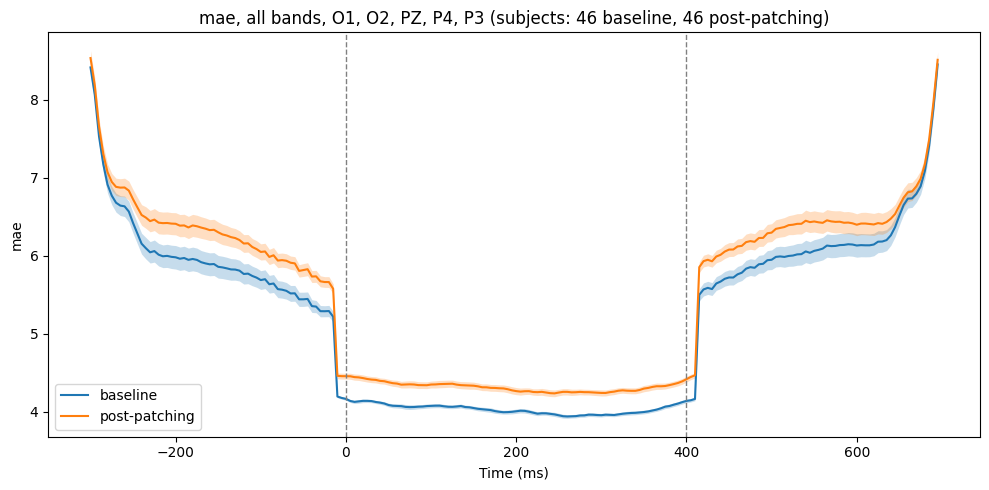

In [17]:
import numpy as np

# time series of one metric in one band, averaged over the selected channels, baseline vs post-patching
ts_metric = "mae"  # one of TS_METRICS: mae, error, target, recon
ts_band = data_processor.ALL_BANDS  # "all bands" or a key of settings.FREQ_BANDS, e.g. "alpha (8-12Hz)"
ts_channels = ["O1", "O2", "PZ", "P4", "P3"]  # short channel names, e.g. ["O1", "O2"]; None averages all channels

# channel names -> indices into the channel dimension (CHORDER_STANDARD order)
short_names = [name.split(' ')[-1].split('-')[0] for name in settings.CHORDER_STANDARD]
ts_channel_idxs = [short_names.index(ch) for ch in ts_channels] if ts_channels is not None else None

# the series always cover the full TIME_WINDOW; the selected time_window is marked with dashed lines
times_ms = (settings.PATCH_WINDOWS["post"][0] + np.arange(settings.TARGET_WINDOW_SIZE) / settings.RSFREQ) * 1000  # start of every post-patch bin
window_ms = [t * 1000 for t in settings.METRIC_WINDOWS[time_window]["post"]]

b_mean, b_sem, b_n = data_processor.get_subjectwise_time_series_mean(baseline_merged, ts_metric, ts_band, ts_channel_idxs)
p_mean, p_sem, p_n = data_processor.get_subjectwise_time_series_mean(postpatch_merged, ts_metric, ts_band, ts_channel_idxs)

channel_text = ", ".join(ts_channels) if ts_channels is not None else "all channels"
fig, ax = plotting.plot_time_series(times_ms, {"baseline": b_mean, "post-patching": p_mean},
                                    sems={"baseline": b_sem, "post-patching": p_sem},
                                    title=f"{ts_metric}, {ts_band}, {channel_text}", y_label=ts_metric,
                                    vlines=sorted({0.0, *window_ms}), n_text=f"subjects: {b_n} baseline, {p_n} post-patching")
plotting.save_button(fig, save_dir=plot_root / "time_series", default_name=f"{ts_metric}_{ts_band}_{'_'.join(ts_channels) if ts_channels else 'all_channels'}_{excl_suffix}")

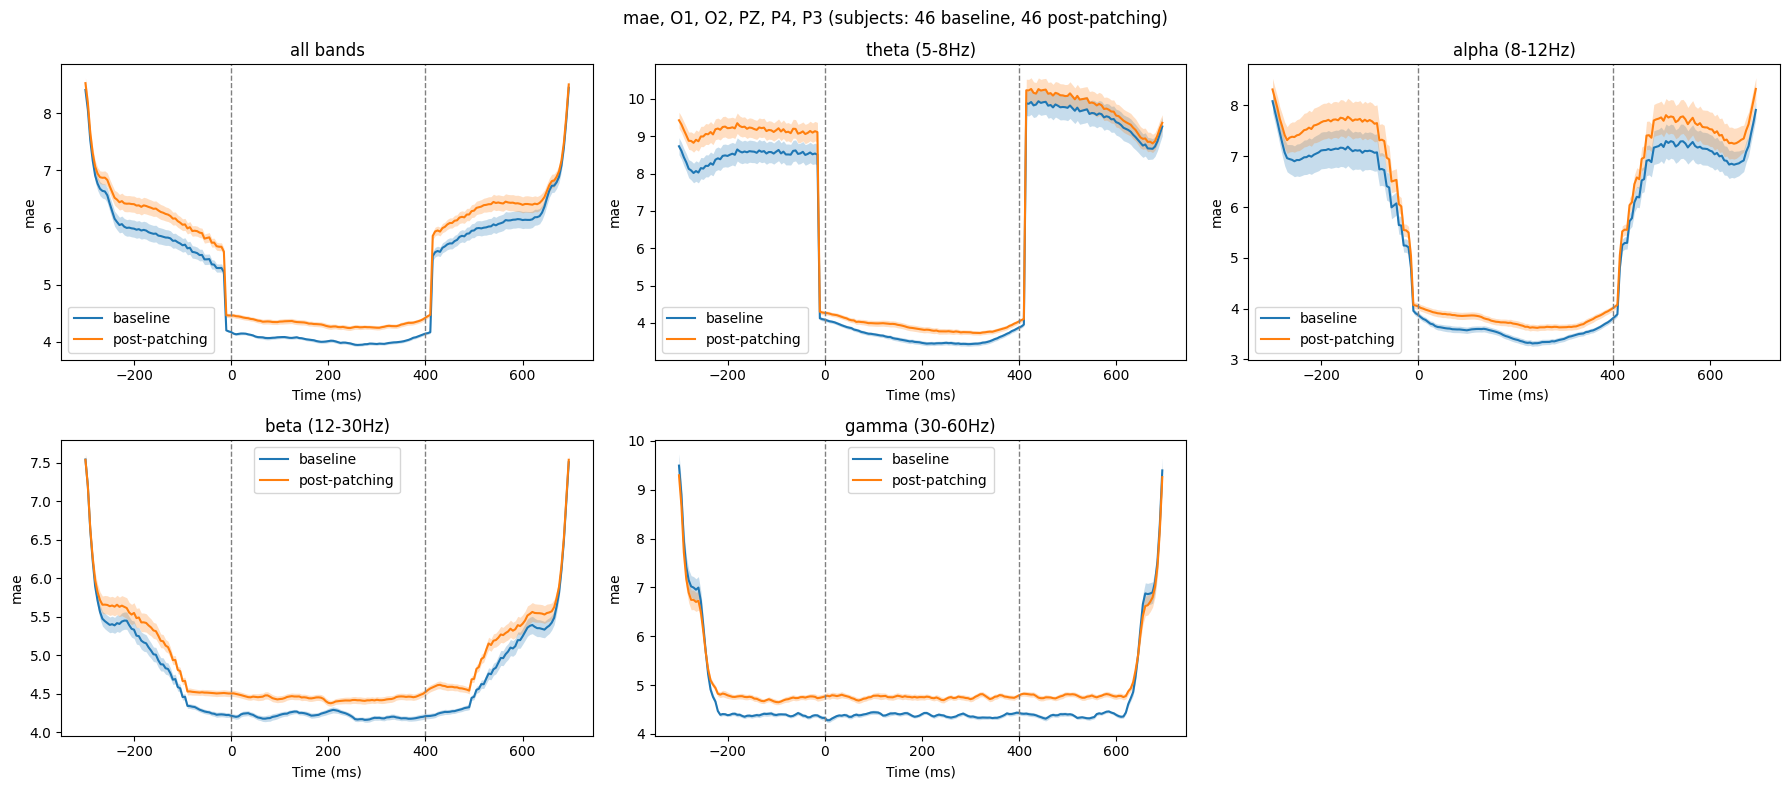

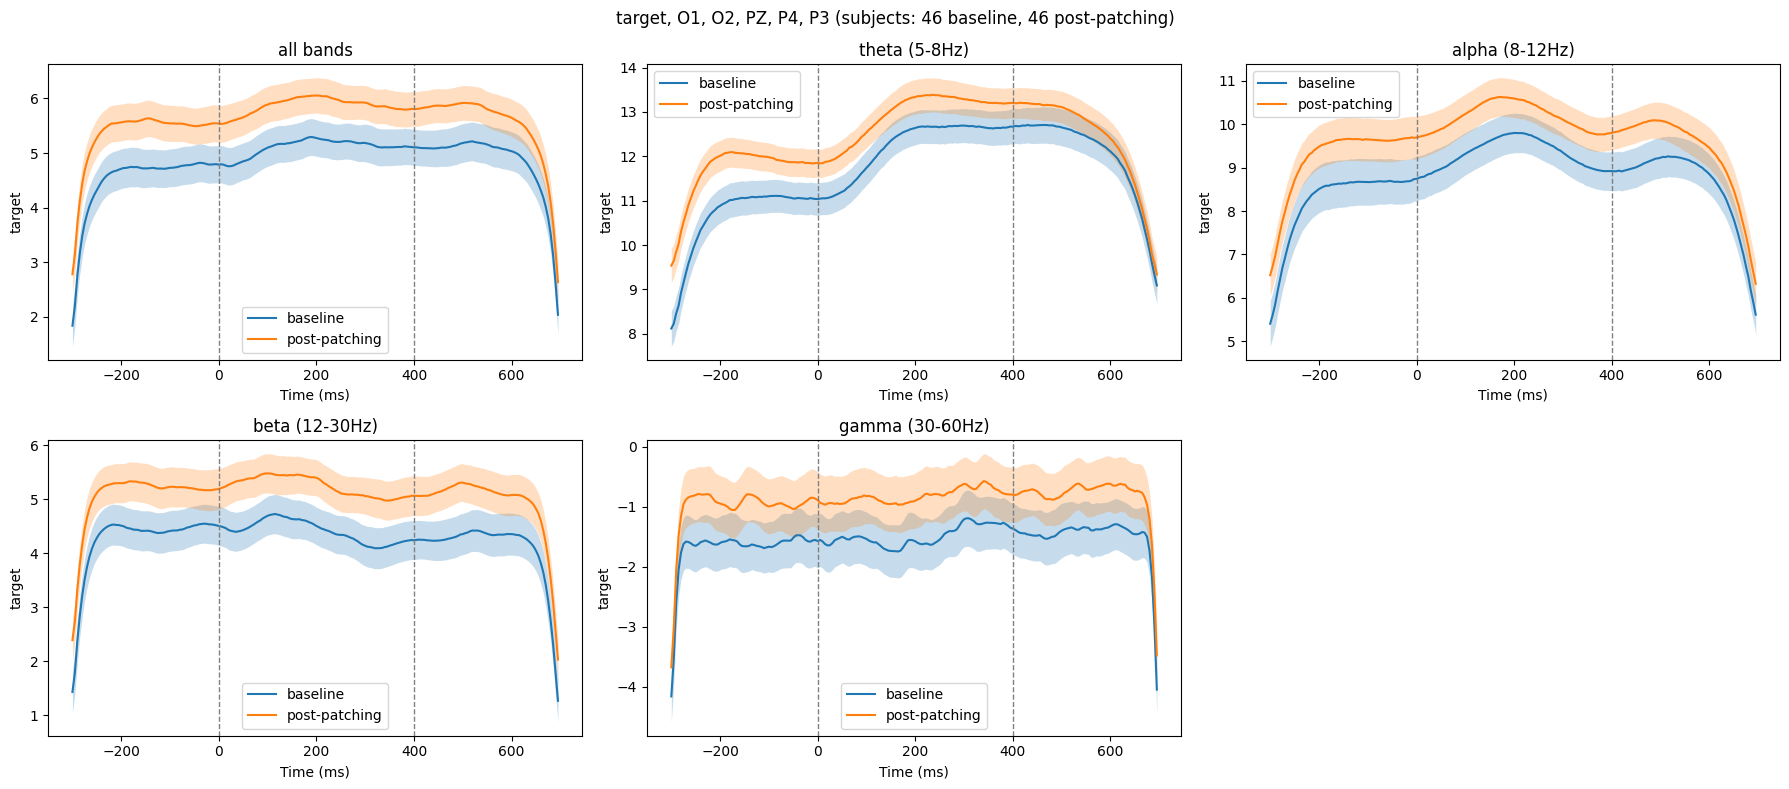

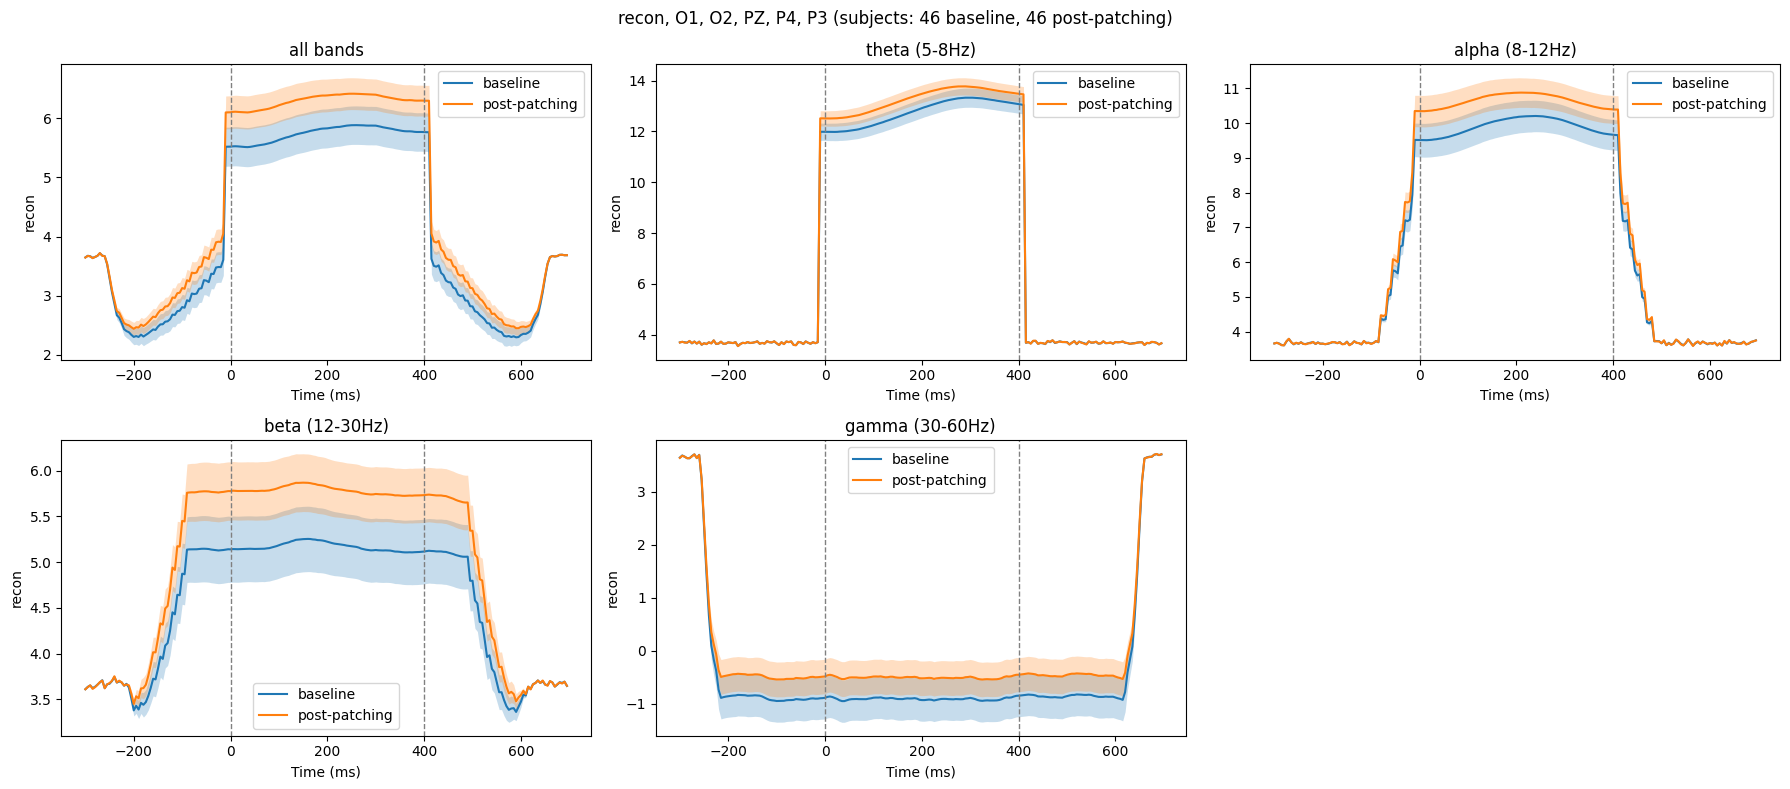

In [18]:
# every band in one figure (all bands + the bands selected above), for the error metric, the target signal and its reconstruction
grid_metrics = [ts_metric, "target", "recon"]  # any of TS_METRICS; "target" is the signal the model reconstructs, "recon" its reconstruction
grid_bands = [data_processor.ALL_BANDS, *bands]

for grid_metric in grid_metrics:
    grid_means, grid_sems = {}, {}
    for band in grid_bands:
        b_mean, b_sem, b_n = data_processor.get_subjectwise_time_series_mean(baseline_merged, grid_metric, band, ts_channel_idxs)
        p_mean, p_sem, p_n = data_processor.get_subjectwise_time_series_mean(postpatch_merged, grid_metric, band, ts_channel_idxs)
        grid_means[band] = {"baseline": b_mean, "post-patching": p_mean}
        grid_sems[band] = {"baseline": b_sem, "post-patching": p_sem}

    fig, axes = plotting.plot_time_series_grid(times_ms, grid_means, sems=grid_sems, y_label=grid_metric,
                                               suptitle=f"{grid_metric}, {channel_text} (subjects: {b_n} baseline, {p_n} post-patching)",
                                               vlines=sorted({0.0, *window_ms}))
    plotting.save_button(fig, save_dir=plot_root / "time_series", default_name=f"{grid_metric}_bands_{'_'.join(ts_channels) if ts_channels else 'all_channels'}_{excl_suffix}")

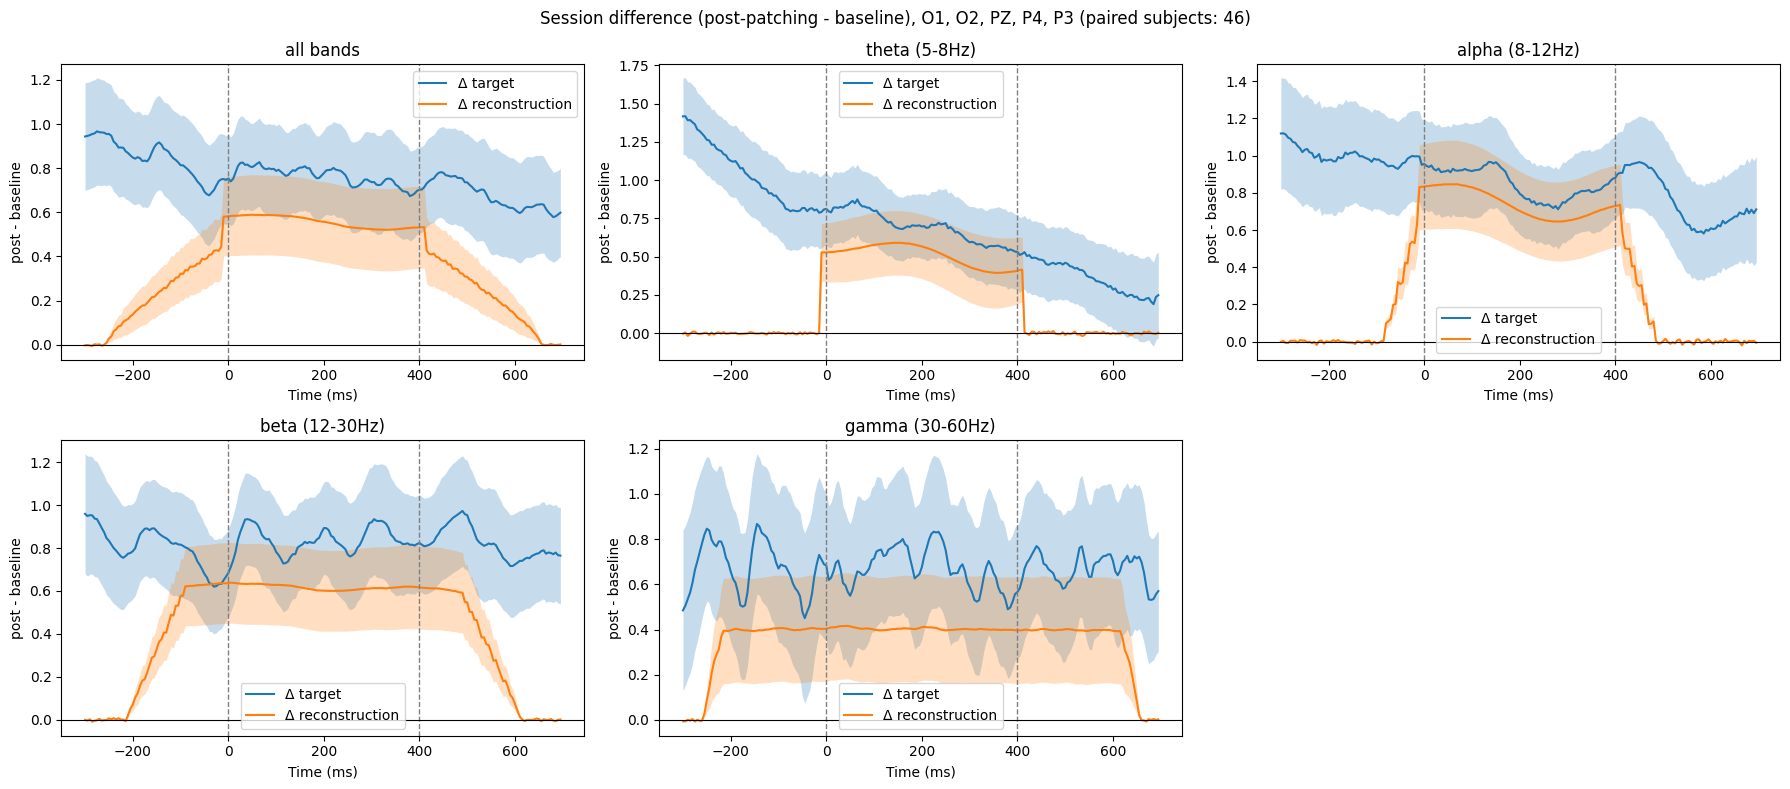

In [19]:
# session differences (post-patching - baseline) of the target and of its reconstruction, per band
# paired per subject: if the model reproduces the change in the signal, the two lines overlap
diff_metrics = {"target": "Δ target", "recon": "Δ reconstruction"}

diff_means, diff_sems = {}, {}
for band in grid_bands:
    diff_means[band], diff_sems[band] = {}, {}
    for metric, label in diff_metrics.items():
        diff_means[band][label], diff_sems[band][label], diff_n = data_processor.get_subjectwise_time_series_difference(
            baseline_merged, postpatch_merged, metric, band, ts_channel_idxs)

fig, axes = plotting.plot_time_series_grid(times_ms, diff_means, sems=diff_sems, y_label="post - baseline",
                                           suptitle=f"Session difference (post-patching - baseline), {channel_text} (paired subjects: {diff_n})",
                                           vlines=sorted({0.0, *window_ms}), hlines=[0.0])
plotting.save_button(fig, save_dir=plot_root / "time_series", default_name=f"session_diff_bands_{'_'.join(ts_channels) if ts_channels else 'all_channels'}_{excl_suffix}")